In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Connect to SQLite database
conn = sqlite3.connect("customers.db")

print("Database connected successfully!")

Database connected successfully!


In [2]:
cursor = conn.cursor()

# Create customers table
cursor.execute("DROP TABLE IF EXISTS customers")

cursor.execute("""
CREATE TABLE customers (
    customer_id INTEGER PRIMARY KEY,
    name TEXT,
    city TEXT,
    age INTEGER
)
""")

# Insert sample customer records
customers = [
    (1, "Jasmine Houston", "Los Angeles", 28),
    (2, "Daniel Smith", "San Diego", 35),
    (3, "Amanda Johnson", "Los Angeles", 30),
    (4, "Michael Brown", "Chicago", 42),
    (5, "Sandra Williams", "Houston", 25),
    (6, "Brandon Davis", "Los Angeles", 33),
    (7, "Angela Martinez", "Phoenix", 29),
    (8, "Anthony Wilson", "San Diego", 38)
]

cursor.executemany("""
INSERT INTO customers
(customer_id, name, city, age)
VALUES (?, ?, ?, ?)
""", customers)

conn.commit()

print("Customers table created successfully!")

df = pd.read_sql("SELECT * FROM customers", conn)
print(df)

Customers table created successfully!
   customer_id             name         city  age
0            1  Jasmine Houston  Los Angeles   28
1            2     Daniel Smith    San Diego   35
2            3   Amanda Johnson  Los Angeles   30
3            4    Michael Brown      Chicago   42
4            5  Sandra Williams      Houston   25
5            6    Brandon Davis  Los Angeles   33
6            7  Angela Martinez      Phoenix   29
7            8   Anthony Wilson    San Diego   38


In [3]:
query1 = """
SELECT *
FROM customers
WHERE city = 'Los Angeles'
"""

result1 = pd.read_sql(query1, conn)

print("Customers from Los Angeles:")
print(result1)

Customers from Los Angeles:
   customer_id             name         city  age
0            1  Jasmine Houston  Los Angeles   28
1            3   Amanda Johnson  Los Angeles   30
2            6    Brandon Davis  Los Angeles   33


In [4]:
query2 = """
SELECT *
FROM customers
ORDER BY age DESC
"""

result2 = pd.read_sql(query2, conn)

print("Customers Sorted by Age:")
print(result2)

Customers Sorted by Age:
   customer_id             name         city  age
0            4    Michael Brown      Chicago   42
1            8   Anthony Wilson    San Diego   38
2            2     Daniel Smith    San Diego   35
3            6    Brandon Davis  Los Angeles   33
4            3   Amanda Johnson  Los Angeles   30
5            7  Angela Martinez      Phoenix   29
6            1  Jasmine Houston  Los Angeles   28
7            5  Sandra Williams      Houston   25


In [5]:
query3 = """
SELECT *
FROM customers
WHERE name LIKE '%an%'
"""

result3 = pd.read_sql(query3, conn)

print("Customers with 'an' in their name:")
print(result3)

Customers with 'an' in their name:
   customer_id             name         city  age
0            2     Daniel Smith    San Diego   35
1            3   Amanda Johnson  Los Angeles   30
2            5  Sandra Williams      Houston   25
3            6    Brandon Davis  Los Angeles   33
4            7  Angela Martinez      Phoenix   29
5            8   Anthony Wilson    San Diego   38


Customers by City:
          city  total_customers
0  Los Angeles                3
1    San Diego                2
2      Phoenix                1
3      Houston                1
4      Chicago                1


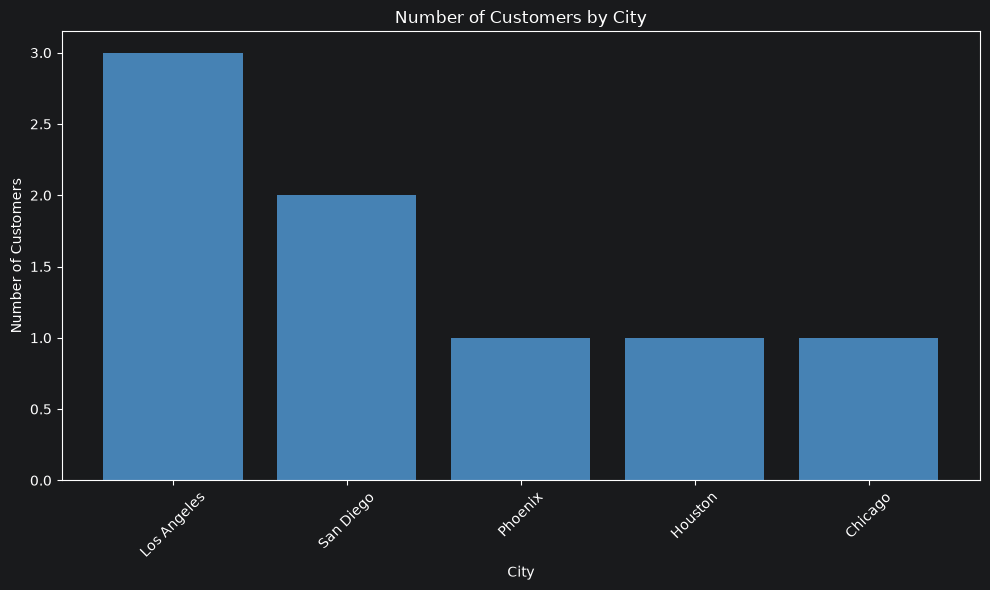

In [7]:
# SQL query to count customers by city
chart_query = """
SELECT city, COUNT(*) AS total_customers
FROM customers
GROUP BY city
ORDER BY total_customers DESC
"""

# Convert SQL result into pandas DataFrame
chart_data = pd.read_sql(chart_query, conn)

print("Customers by City:")
print(chart_data)

# Create bar chart
plt.figure(figsize=(10, 6))

plt.bar(
    chart_data["city"],
    chart_data["total_customers"],
    color="steelblue"
)

plt.title("Number of Customers by City")
plt.xlabel("City")
plt.ylabel("Number of Customers")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
# SQL Query Analysis
# I chose to compare the number of customers in each city. I used an SQL query with COUNT and GROUP BY to organize the data, then transferred the results into pandas to create a bar chart. This helped me understand how SQL and Python can work together to analyze information and make the results easier to understand.

In [9]:
# How AI Helped Me
#AI helped me understand how to write SQL queries using WHERE, ORDER BY, and LIKE.